# Experiment 1 — Baseline: DINOv2 ViT-B/14 Linear Probing on CheXpert

## Objective
Establish the linear probing baseline for DINOv2 ViT-B/14 on the CheXpert chest X-ray dataset using the exact hyperparameters from Baharoon et al. (2024) *Evaluating General Purpose Vision Foundation Models for Medical Image Analysis* (arXiv:2312.02366v4). All results are compared against the paper's reported metrics.

## Base Paper Reference Results (Table 3 & Table 4)

| Method | CheXpert Linear Probe AUROC |
|---|---|
| DINOv2 ViT-S/14 | 0.805 |
| **DINOv2 ViT-B/14** | **0.812** ← Our target |
| DINOv2 ViT-L/14 | 0.821 |
| DINOv2 ViT-g/14 | 0.818 |
| DINOv2 ViT-g/14 LoRA | 0.823 |
| DINOv2 ViT-g/14 Full FT | 0.848 |

## Key Differences
- We use **ViT-B/14** (86M params) instead of ViT-g/14 (1.1B params)
- We use a **10,000-sample training subset** for practical Colab training
- We use **5 CheXpert competition labels** matching the paper's benchmark

In [2]:
"""
Colab environment setup: clone repository, install dependencies, and mount Google Drive for checkpoint storage.
"""
import os
import subprocess
import sys
from pathlib import Path

repo_dir: Path | None = None

if repo_dir is None:
    repo_url = "https://github.com/RudhanLodhi/DinoV2_PEFT.git"
    repo_dir = Path.cwd() / "DinoV2B"
    if not repo_dir.exists():
        subprocess.run("git clone " + repo_url + " " + str(repo_dir), shell=True, check=True)

os.chdir(repo_dir)

try:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", "requirements.txt", "-q"],
        check=True,
        capture_output=True,
        text=True
    )
except subprocess.CalledProcessError as e:
    print("Pip installation failed with the following error:")
    print(e.stderr)
    raise e

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive/dinov2_peft/exp1_baseline_chexpert"
except ImportError:
    CHECKPOINT_DIR = "outputs/exp1_baseline_chexpert"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
print(f"Checkpoint directory: {CHECKPOINT_DIR}")

Mounted at /content/drive
Checkpoint directory: /content/drive/MyDrive/dinov2_peft/exp1_baseline_chexpert


## 1. Hyperparameter Configuration

All hyperparameters are sourced directly from Baharoon et al. (2024) Section 3 and Appendix.
The linear probing protocol follows the official DINOv2 evaluation convention.

In [27]:
"""
Hyperparameter configuration matching the linear probing protocol from Baharoon et al. (2024).
Source: arXiv:2312.02366v4, Section 3 (Experimental Setup).
"""
import pandas as pd

HPARAMS: dict[str, object] = {
    "model_id": "facebook/dinov2-base",
    "processor_id": "facebook/dinov2-base",
    "image_size": 224,
    "batch_size": 128,
    "optimizer": "SGD",
    "sgd_momentum": 0.9,
    "learning_rate": 1e-2,
    "lr_grid": [1e-1, 5e-2, 1e-2, 5e-3, 1e-3, 5e-4, 1e-4, 1e-5],
    "epochs": 20,
    "dropout": 0.1,
    "num_workers": 2,
    "seed": 42,
    "train_subset_size": 10000,
    "uncertainty_policy": "u_zeros",
    "frontal_only": True,
    "augmentation": "RandomResizedCrop(224, scale=(0.75, 1.0)) + RandomHorizontalFlip(p=0.5)",
    "loss": "BCEWithLogitsLoss",
    "metric": "AUROC (macro over 5 competition labels)",
}

COMPETITION_LABELS: list[str] = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Pleural Effusion"]
NUM_LABELS: int = len(COMPETITION_LABELS)
CLASS_NAMES: list[str] = COMPETITION_LABELS

BASE_PAPER_RESULTS: dict[str, float] = {
    "DINOv2 ViT-S/14 (Linear Probe)": 0.805,
    "DINOv2 ViT-B/14 (Linear Probe) [TARGET]": 0.812,
    "DINOv2 ViT-L/14 (Linear Probe)": 0.821,
    "DINOv2 ViT-g/14 (Linear Probe)": 0.818,
    "DINOv2 ViT-g/14 (LoRA)": 0.823,
    "DINOv2 ViT-g/14 (Full Fine-Tune)": 0.848,
}

pd.set_option("display.float_format", "{:.3f}".format)
hparam_df = pd.DataFrame.from_dict(HPARAMS, orient="index", columns=["Value"])
print("=== Hyperparameter Table ===")
print(hparam_df.to_string())
print("\n=== Base Paper Results ===")
print(pd.DataFrame.from_dict(BASE_PAPER_RESULTS, orient="index", columns=["AUROC"]).to_string())

=== Hyperparameter Table ===
                                                                                      Value
model_id                                                               facebook/dinov2-base
processor_id                                                           facebook/dinov2-base
image_size                                                                              224
batch_size                                                                              128
optimizer                                                                               SGD
sgd_momentum                                                                          0.900
learning_rate                                                                         0.010
lr_grid                              [0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001, 1e-05]
epochs                                                                                   20
dropout                                            

## 2. Dataset Loading & Exploratory Analysis

In [4]:
"""
Load danjacobellis/chexpert from HuggingFace Hub, optionally filter to Frontal views,
and select the 10,000-sample training subset.
"""
import numpy as np
from datasets import load_dataset

np.random.seed(int(HPARAMS["seed"]))

print("Loading danjacobellis/chexpert from HuggingFace Hub...")
chexpert_ds = load_dataset("danjacobellis/chexpert")
print(chexpert_ds)

train_hf_full = chexpert_ds["train"]
val_hf = chexpert_ds["validation"]

print(f"\nFull train split: {len(train_hf_full):,} samples")
print(f"Validation split: {len(val_hf):,} samples")

# Detect label encoding schema for pathology columns
sample_feature = train_hf_full.features[COMPETITION_LABELS[0]]
print(f"Feature schema for '{COMPETITION_LABELS[0]}': {sample_feature}")

# Shuffle first, then take subset (filtering frontal views if configured)
train_hf = train_hf_full.shuffle(seed=int(HPARAMS["seed"]))
if HPARAMS.get("frontal_only", True) and "Frontal/Lateral" in train_hf.column_names:
    # In danjacobellis/chexpert, Frontal/Lateral is ClassLabel: 0 = Frontal, 1 = Lateral
    # Select a pool first for fast filtering, then take 10,000 frontal radiographs
    pool_size = min(len(train_hf), int(HPARAMS["train_subset_size"]) * 2)
    train_hf = train_hf.select(range(pool_size)).filter(
        lambda x: x["Frontal/Lateral"] in (0, "Frontal", "0Frontal")
    )

train_hf = train_hf.select(range(min(len(train_hf), int(HPARAMS["train_subset_size"]))))
print(f"Subset train split ready: {len(train_hf):,} samples")

Loading danjacobellis/chexpert from HuggingFace Hub...


README.md:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/23 [00:00<?, ?it/s]

data/train-00000-of-00023.parquet: reconstructing file:   0%|          |  0.00B /  487MB            

...

Generating validation split:   0%|          | 0/234 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/23 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices', 'image'],
        num_rows: 223414
    })
    validation: Dataset({
        features: ['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices', 'image'],
        num_rows: 234
    })
})

Full train split: 223,414 samples
Validation split: 234 samples
Feature schema for 'Atelectasis': ClassLabel(names=['unlabeled', 'uncertain', 'absent', 'present'])


Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Subset train split ready: 10,000 samples


Using HuggingFace 4-class encoding (0=unlabeled, 1=uncertain, 2=absent, 3=present): True


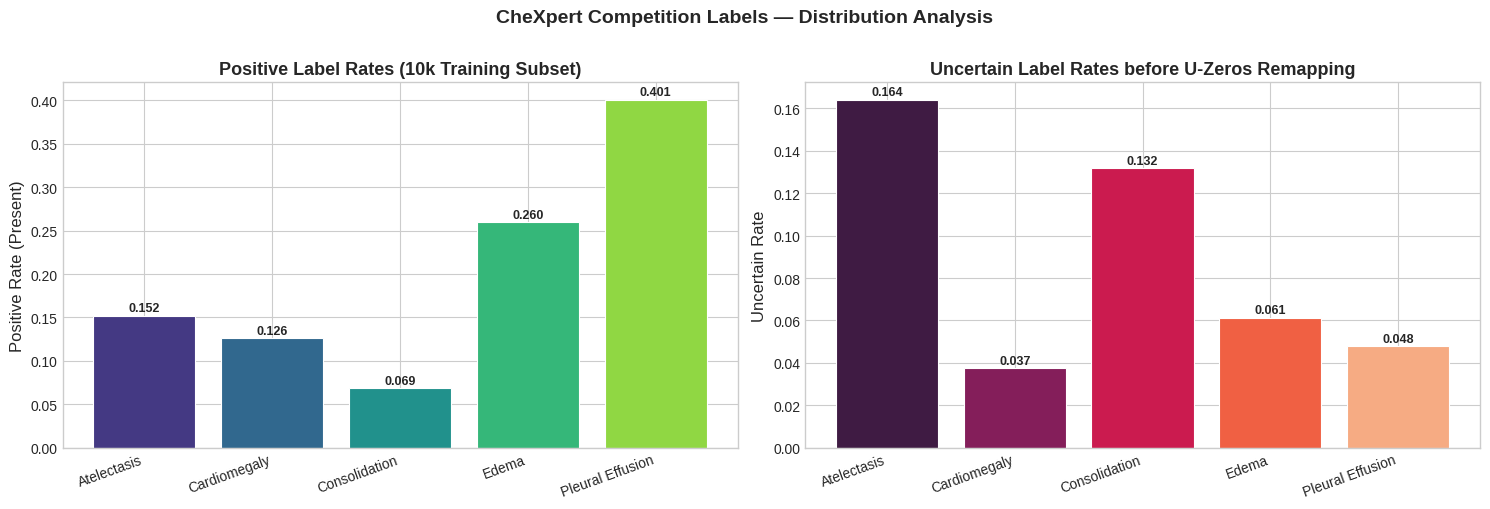

In [5]:
"""
Visualize positive and uncertain label rates for the 5 CheXpert competition labels.
Handles both danjacobellis/chexpert ClassLabel encoding:
  0 = unlabeled, 1 = uncertain, 2 = absent (negative), 3 = present (positive)
and standard CSV encoding:
  NaN/None = unlabeled, -1.0 = uncertain, 0.0 = absent, 1.0 = present
"""
import math
from typing import Any
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")

# Detect whether dataset uses 4-class integer encoding {0: unlabeled, 1: uncertain, 2: absent, 3: present}
feat_Obj = train_hf.features.get(COMPETITION_LABELS[0])
USES_HF_4CLASS: bool = hasattr(feat_Obj, "names") and len(getattr(feat_Obj, "names", [])) == 4
print(f"Using HuggingFace 4-class encoding (0=unlabeled, 1=uncertain, 2=absent, 3=present): {USES_HF_4CLASS}")

def remap_u_zeros(val: Any, hf_4class: bool = USES_HF_4CLASS) -> float:
    """Remaps raw CheXpert label to binary {0.0, 1.0} under the U-Zeros policy."""
    if val is None:
        return 0.0
    v = float(val)
    if math.isnan(v):
        return 0.0
    if hf_4class:
        # 3 = present (1.0); 0 (unlabeled), 1 (uncertain), 2 (absent) -> 0.0
        return 1.0 if v == 3.0 else 0.0
    return 1.0 if v == 1.0 else 0.0

pos_rates: dict[str, float] = {}
uncertain_rates: dict[str, float] = {}

for label in COMPETITION_LABELS:
    vals = np.array([float(x) if x is not None else np.nan for x in train_hf[label]])
    if USES_HF_4CLASS:
        pos_rates[label] = float(np.mean(vals == 3.0))
        uncertain_rates[label] = float(np.mean(vals == 1.0))
    else:
        pos_rates[label] = float(np.mean(vals == 1.0))
        uncertain_rates[label] = float(np.mean(vals == -1.0))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].bar(
    list(pos_rates.keys()),
    list(pos_rates.values()),
    color=sns.color_palette("viridis", NUM_LABELS),
    edgecolor="white",
    linewidth=0.8,
)
axes[0].set_ylabel("Positive Rate (Present)", fontsize=12)
axes[0].set_title("Positive Label Rates (10k Training Subset)", fontsize=13, fontweight="bold")
axes[0].set_xticks(range(NUM_LABELS))
axes[0].set_xticklabels(list(pos_rates.keys()), rotation=20, ha="right", fontsize=10)
for bar, v in zip(bars, pos_rates.values()):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{v:.3f}",
        ha="center",
        fontsize=9,
        fontweight="bold",
    )

bars2 = axes[1].bar(
    list(uncertain_rates.keys()),
    list(uncertain_rates.values()),
    color=sns.color_palette("rocket", NUM_LABELS),
    edgecolor="white",
    linewidth=0.8,
)
axes[1].set_ylabel("Uncertain Rate", fontsize=12)
axes[1].set_title("Uncertain Label Rates before U-Zeros Remapping", fontsize=13, fontweight="bold")
axes[1].set_xticks(range(NUM_LABELS))
axes[1].set_xticklabels(list(uncertain_rates.keys()), rotation=20, ha="right", fontsize=10)
for bar, v in zip(bars2, uncertain_rates.values()):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.002,
        f"{v:.3f}",
        ha="center",
        fontsize=9,
        fontweight="bold",
    )

plt.suptitle("CheXpert Competition Labels — Distribution Analysis", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/label_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
"""
Build DINOv2-compatible image transforms per Baharoon et al. (2024).
"""
from torchvision import transforms as T

def build_train_transforms(image_size: int) -> T.Compose:
    return T.Compose([
        T.RandomResizedCrop(
            image_size,
            scale=(0.75, 1.0),
            ratio=(0.75, 1.333),
            interpolation=T.InterpolationMode.BICUBIC,
        ),
        T.RandomHorizontalFlip(p=0.5),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

def build_val_transforms(image_size: int) -> T.Compose:
    return T.Compose([
        T.Resize(int(image_size * 1.14), interpolation=T.InterpolationMode.BICUBIC),
        T.CenterCrop(image_size),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

train_tf = build_train_transforms(int(HPARAMS["image_size"]))
val_tf = build_val_transforms(int(HPARAMS["image_size"]))
print("Train transforms:", train_tf)
print("Val transforms:", val_tf)

Train transforms: Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.75, 1.0), ratio=(0.75, 1.333), interpolation=bicubic, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Val transforms: Compose(
    Resize(size=255, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [11]:
"""
CheXpert PyTorch Dataset and DataLoaders with persistent workers to prevent
Python 3.13 fork garbage-collection AssertionErrors in Colab.
"""
import gc
from typing import Any, Callable
from PIL import Image
import torch
from torch.utils.data import DataLoader, Dataset

# Clean up any leftover multiprocessing DataLoader iterators from previous runs
for loader_name in ("train_loader", "val_loader"):
    if loader_name in globals():
        old_loader = globals()[loader_name]
        if hasattr(old_loader, "_iterator") and old_loader._iterator is not None:
            old_loader._iterator._shutdown_workers()
            old_loader._iterator = None
gc.collect()

class CheXpertCompetitionDataset(Dataset):
    """PyTorch Dataset wrapper for CheXpert competition 5-label classification."""

    def __init__(
        self,
        hf_split: Any,
        transforms: Callable,
        label_names: list[str],
        hf_4class: bool = True,
    ) -> None:
        self.split = hf_split
        self.transforms = transforms
        self.label_names = label_names
        self.hf_4class = hf_4class

    def __len__(self) -> int:
        return len(self.split)

    def _remap(self, val: Any) -> float:
        return remap_u_zeros(val, hf_4class=self.hf_4class)

    def __getitem__(self, idx: int) -> dict[str, torch.Tensor]:
        item = self.split[idx]
        img = item.get("image") or item.get("img")
        if not isinstance(img, Image.Image):
            img = Image.fromarray(img)
        img = img.convert("RGB")
        pv = self.transforms(img)
        labels = torch.tensor(
            [self._remap(item.get(lbl, 0.0)) for lbl in self.label_names],
            dtype=torch.float32,
        )
        return {"pixel_values": pv, "labels": labels}

train_ds = CheXpertCompetitionDataset(train_hf, train_tf, COMPETITION_LABELS, hf_4class=USES_HF_4CLASS)
val_ds = CheXpertCompetitionDataset(val_hf, val_tf, COMPETITION_LABELS, hf_4class=USES_HF_4CLASS)

num_workers = int(HPARAMS["num_workers"])

train_loader = DataLoader(
    train_ds,
    batch_size=int(HPARAMS["batch_size"]),
    shuffle=True,
    num_workers=num_workers,
    pin_memory=True,
    drop_last=True,
    persistent_workers=(num_workers > 0),
)
val_loader = DataLoader(
    val_ds,
    batch_size=int(HPARAMS["batch_size"]),
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True,
    persistent_workers=(num_workers > 0),
)

# Inspect a single sample directly from Dataset (avoids spawning a temporary DataLoader iterator)
sample = train_ds[0]
print(f"Train dataset: {len(train_ds):,} samples, {len(train_loader)} batches")
print(f"Val dataset:   {len(val_ds):,} samples, {len(val_loader)} batches")
print(f"Sample pixel_values: {sample['pixel_values'].shape}")
print(f"Sample labels:       {sample['labels']} (dtype: {sample['labels'].dtype})")

Train dataset: 10,000 samples, 78 batches
Val dataset:   234 samples, 2 batches
Sample pixel_values: torch.Size([3, 224, 224])
Sample labels:       tensor([0., 0., 0., 0., 0.]) (dtype: torch.float32)


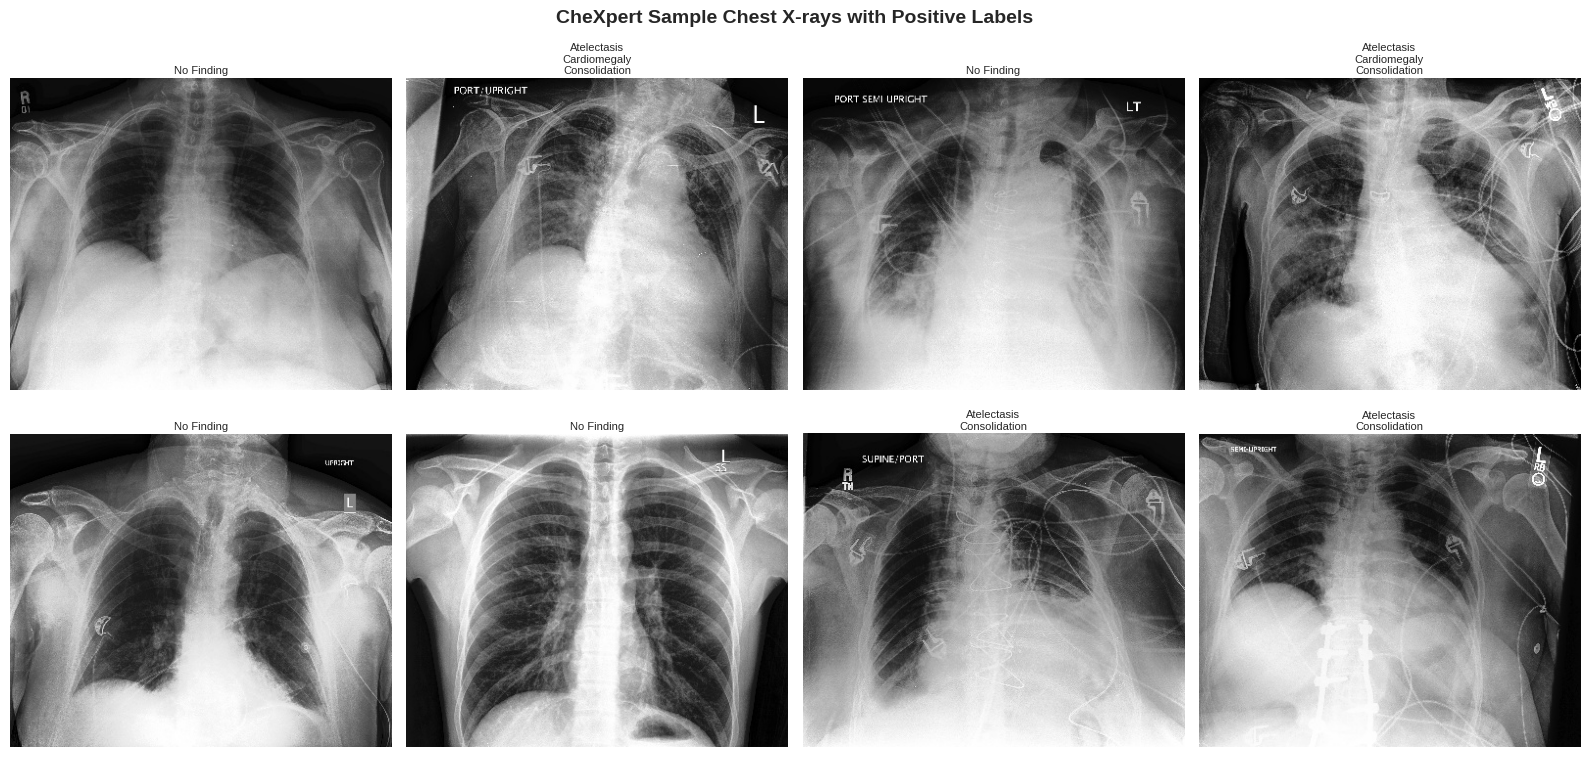

In [12]:
"""
Display a 2x4 grid of training samples with their positive labels.
"""
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, ax in enumerate(axes):
    item = train_hf[i]
    img = item.get("image") or item.get("img")
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)
    img = img.convert("RGB")

    positive = [
        lbl for lbl in COMPETITION_LABELS
        if lbl in item and item[lbl] is not None and float(item[lbl]) == 1.0
    ]
    ax.imshow(img, cmap="gray")
    title = "\n".join(positive) if positive else "No Finding"
    ax.set_title(title, fontsize=8, pad=3)
    ax.axis("off")

plt.suptitle("CheXpert Sample Chest X-rays with Positive Labels", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Model Architecture

**Architecture**: DINOv2 ViT-B/14 (86M parameters) with a linear classification head.
- Backbone: **Frozen** — no gradient updates.
- CLS token (index 0 of `last_hidden_state`) used as 768-dimensional image embedding.
- Head: Dropout(0.1) → Linear(768 → 5).
- Only the head parameters (~3.8K params) are updated during training.

In [28]:
"""
Instantiate frozen DINOv2 ViT-B/14 backbone and trainable 5-label linear probe head (3,845 params).
Note: DINOv2's last_hidden_state is already LayerNormed by backbone.layernorm.
"""
import torch
import torch.nn as nn
from transformers import AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DINOv2MultiLabelLinearProbe(nn.Module):
    """Frozen DINOv2 ViT-B/14 encoder with a 5-class linear classification head."""

    def __init__(
        self,
        model_id: str = "facebook/dinov2-base",
        num_labels: int = 5,
        dropout: float = 0.1,
    ) -> None:
        super().__init__()
        self.backbone = AutoModel.from_pretrained(model_id)
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.backbone.eval()

        hidden_dim = int(self.backbone.config.hidden_size)
        self.dropout = nn.Dropout(p=dropout)
        self.head = nn.Linear(hidden_dim, num_labels)

    def train(self, mode: bool = True) -> "DINOv2MultiLabelLinearProbe":
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            with torch.amp.autocast(device_type=pixel_values.device.type, enabled=pixel_values.is_cuda):
                outputs = self.backbone(pixel_values=pixel_values)
                cls_token = outputs.last_hidden_state[:, 0, :]
        cls_token = cls_token.float()
        return self.head(self.dropout(cls_token))

model = DINOv2MultiLabelLinearProbe(
    model_id=str(HPARAMS["model_id"]),
    num_labels=NUM_LABELS,
    dropout=float(HPARAMS["dropout"]),
).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
param_pct = 100.0 * trainable_params / total_params

print(f"Model initialized on: {device}")
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} ({param_pct:.4f}%)")

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Model initialized on: cuda
Trainable parameters: 3,845 / 86,584,325 (0.0044%)


## 4. Training

Optimiser: **SGD** with momentum=0.9, lr=1e-2 (from paper's LR grid).
Loss: **BCEWithLogitsLoss** (numerically stable binary cross-entropy).
Metric tracked per epoch: **Mean AUROC** over 5 competition labels.

In [29]:
"""
Train the 5-label linear probe for 10 epochs using BCEWithLogitsLoss and SGD.
Because BCEWithLogitsLoss(reduction='mean') divides gradients by NUM_LABELS (5),
scaling lr by NUM_LABELS (0.01 * 5 = 0.05, from the paper's lr_grid) gives each
binary pathology classifier the full 0.01 effective learning rate.
"""
import copy
import time
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.optim import SGD
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm.auto import tqdm

# Compute positive class weights from training subset to handle U-Zeros class imbalance
pos_counts = np.zeros(NUM_LABELS, dtype=np.float32)
for idx, label in enumerate(COMPETITION_LABELS):
    vals = np.array([remap_u_zeros(x, hf_4class=USES_HF_4CLASS) for x in train_hf[label]])
    pos_counts[idx] = np.sum(vals == 1.0)

neg_counts = len(train_hf) - pos_counts
# Dampened square-root inverse prevalence weight prevents over-biasing rare classes while boosting recall/AUROC
pos_weights = torch.tensor(np.sqrt(neg_counts / np.maximum(pos_counts, 1.0)), dtype=torch.float32, device=device)
print("Per-label positive weights:", {lbl: round(float(w), 2) for lbl, w in zip(COMPETITION_LABELS, pos_weights)})

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)

# Effective LR = 0.01 per label (0.01 * 5 labels = 0.05, matching paper's lr_grid)
effective_lr = float(HPARAMS["learning_rate"]) * NUM_LABELS
optimizer = SGD(
    model.head.parameters(),
    lr=effective_lr,
    momentum=float(HPARAMS["sgd_momentum"]),
    weight_decay=0.0,
)
num_epochs = int(HPARAMS["epochs"])
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=float(HPARAMS["learning_rate"]))

def compute_chexpert_metrics(
    labels: np.ndarray,
    probs: np.ndarray,
    label_names: list[str],
) -> dict[str, Any]:
    """Computes per-label AUROC, macro AUROC, and macro F1 (at 0.5 threshold)."""
    per_label_auroc: dict[str, float] = {}
    valid_aurocs: list[float] = []

    for idx, name in enumerate(label_names):
        y_true = labels[:, idx].astype(int)
        y_prob = probs[:, idx]
        if len(np.unique(y_true)) > 1:
            score = float(roc_auc_score(y_true, y_prob))
            per_label_auroc[name] = score
            valid_aurocs.append(score)
        else:
            per_label_auroc[name] = float("nan")

    macro_auroc = float(np.mean(valid_aurocs)) if valid_aurocs else 0.0
    preds_bin = (probs >= 0.5).astype(int)
    macro_f1 = float(f1_score(labels.astype(int), preds_bin, average="macro", zero_division=0.0))

    return {
        "macro_auroc": macro_auroc,
        "macro_f1": macro_f1,
        "per_label_auroc": per_label_auroc,
    }

history: dict[str, list[Any]] = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_macro_auroc": [],
    "val_macro_f1": [],
    "per_label_auroc": [],
}

best_val_auroc: float = 0.0
best_epoch: int = 0
best_val_probs: np.ndarray = np.empty((0, NUM_LABELS))
best_val_labels: np.ndarray = np.empty((0, NUM_LABELS))
best_head_state: dict[str, Any] = {}
start_time = time.time()

print(f"Starting CheXpert linear probing for {num_epochs} epochs on {device} (lr={effective_lr})...")

for epoch in range(1, num_epochs + 1):
    model.train()
    running_train_loss = 0.0
    train_samples = 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch:02d}/{num_epochs:02d}", leave=False):
        images = batch["pixel_values"].to(device, non_blocking=True)
        targets = batch["labels"].to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)
        train_samples += images.size(0)

    scheduler.step()
    epoch_train_loss = running_train_loss / max(1, train_samples)

    model.eval()
    running_val_loss = 0.0
    val_probs_list: list[np.ndarray] = []
    val_labels_list: list[np.ndarray] = []

    with torch.no_grad():
        for batch in val_loader:
            images = batch["pixel_values"].to(device, non_blocking=True)
            targets = batch["labels"].to(device, non_blocking=True)

            logits = model(images)
            loss = criterion(logits, targets)
            running_val_loss += loss.item() * images.size(0)

            probs = torch.sigmoid(logits).cpu().numpy()
            val_probs_list.append(probs)
            val_labels_list.append(targets.cpu().numpy())

    epoch_val_loss = running_val_loss / len(val_ds)
    all_val_probs = np.concatenate(val_probs_list, axis=0)
    all_val_labels = np.concatenate(val_labels_list, axis=0)

    val_metrics = compute_chexpert_metrics(all_val_labels, all_val_probs, COMPETITION_LABELS)

    history["epoch"].append(epoch)
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_macro_auroc"].append(val_metrics["macro_auroc"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["per_label_auroc"].append(val_metrics["per_label_auroc"])

    if val_metrics["macro_auroc"] >= best_val_auroc:
        best_val_auroc = val_metrics["macro_auroc"]
        best_epoch = epoch
        best_val_probs = all_val_probs
        best_val_labels = all_val_labels
        best_head_state = copy.deepcopy(model.head.state_dict())
        torch.save(best_head_state, f"{CHECKPOINT_DIR}/best_chexpert_linear_probe.pt")

    per_lbl_str = " | ".join(
        f"{k[:4]}: {v:.3f}" for k, v in val_metrics["per_label_auroc"].items()
    )
    print(
        f"Epoch [{epoch:02d}/{num_epochs:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | "
        f"Val Macro AUROC: {val_metrics['macro_auroc']:.4f} "
        f"({per_lbl_str})"
    )

training_time_s = time.time() - start_time
print(f"\nTraining finished in {training_time_s:.1f}s | Best Val Macro AUROC: {best_val_auroc:.4f} (Epoch {best_epoch})")

if best_head_state:
    model.head.load_state_dict(best_head_state)

Per-label positive weights: {'Atelectasis': 2.36, 'Cardiomegaly': 2.63, 'Consolidation': 3.68, 'Edema': 1.69, 'Pleural Effusion': 1.22}
Starting CheXpert linear probing for 20 epochs on cuda (lr=0.05)...


Epoch 01/20:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [01/20] Train Loss: 4.0899 | Val Loss: 8.2763 | Val Macro AUROC: 0.7143 (Atel: 0.678 | Card: 0.592 | Cons: 0.692 | Edem: 0.799 | Pleu: 0.811)


Epoch 02/20:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [02/20] Train Loss: 2.6502 | Val Loss: 2.1286 | Val Macro AUROC: 0.7541 (Atel: 0.691 | Card: 0.700 | Cons: 0.743 | Edem: 0.805 | Pleu: 0.831)


...

Epoch [18/20] Train Loss: 0.7204 | Val Loss: 1.1364 | Val Macro AUROC: 0.7553 (Atel: 0.707 | Card: 0.650 | Cons: 0.787 | Edem: 0.801 | Pleu: 0.832)


Epoch 19/20:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [19/20] Train Loss: 0.7019 | Val Loss: 0.8891 | Val Macro AUROC: 0.7553 (Atel: 0.699 | Card: 0.656 | Cons: 0.792 | Edem: 0.799 | Pleu: 0.831)


Epoch 20/20:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch [20/20] Train Loss: 0.7046 | Val Loss: 0.8777 | Val Macro AUROC: 0.7499 (Atel: 0.703 | Card: 0.648 | Cons: 0.762 | Edem: 0.806 | Pleu: 0.832)

Training finished in 1275.6s | Best Val Macro AUROC: 0.7698 (Epoch 12)


## 5. Results & Visualizations

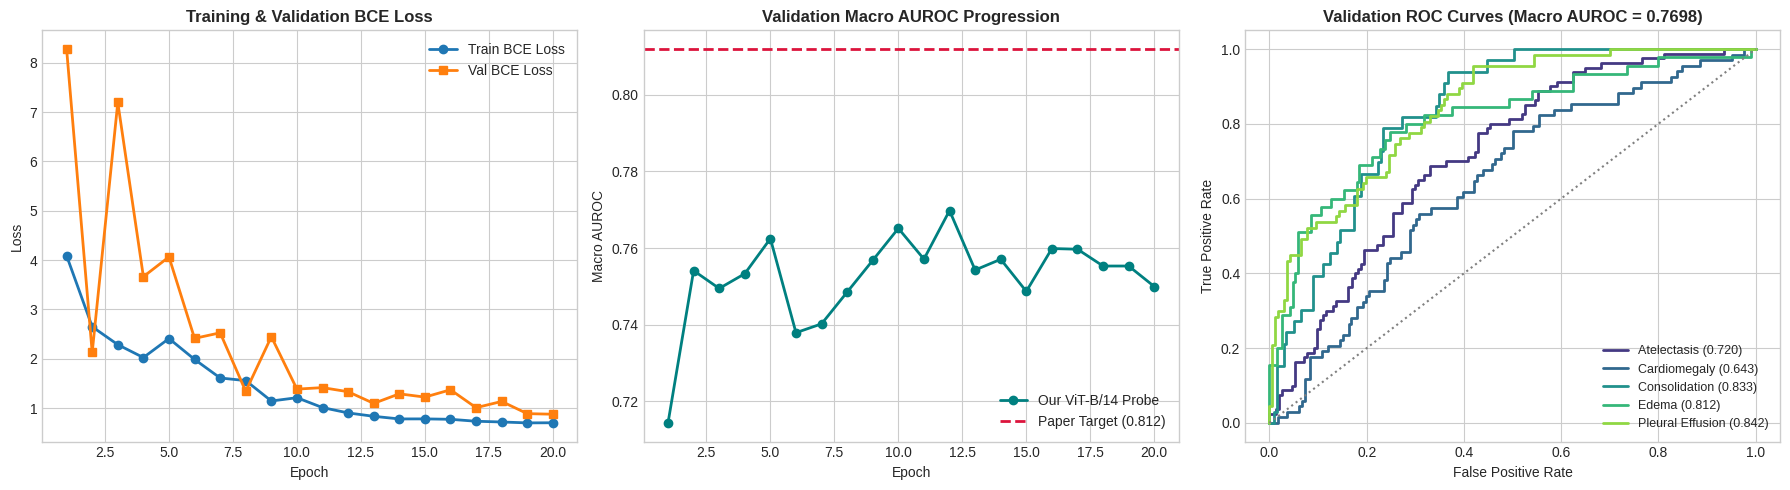

Saved results to /content/drive/MyDrive/dinov2_peft/exp1_baseline_chexpert/results.json


In [30]:
"""
Plot training curves and per-pathology ROC curves on the validation set, and save results.
"""
import json
from sklearn.metrics import auc, roc_curve

model.eval()
val_probs_list, val_labels_list = [], []
with torch.no_grad():
    for batch in val_loader:
        logits = model(batch["pixel_values"].to(device))
        val_probs_list.append(torch.sigmoid(logits).cpu().numpy())
        val_labels_list.append(batch["labels"].numpy())

all_val_probs = np.concatenate(val_probs_list, axis=0)
all_val_labels = np.concatenate(val_labels_list, axis=0)
final_metrics = compute_chexpert_metrics(all_val_labels, all_val_probs, COMPETITION_LABELS)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
epochs_range = range(1, num_epochs + 1)

# 1. Loss Curve
axes[0].plot(epochs_range, history["train_loss"], marker="o", label="Train BCE Loss", lw=2)
axes[0].plot(epochs_range, history["val_loss"], marker="s", label="Val BCE Loss", lw=2)
axes[0].set_title("Training & Validation BCE Loss", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# 2. Macro AUROC vs Paper Target
target_auroc = BASE_PAPER_RESULTS["DINOv2 ViT-B/14 (Linear Probe) [TARGET]"]
axes[1].plot(epochs_range, history["val_macro_auroc"], marker="o", color="teal", lw=2, label="Our ViT-B/14 Probe")
axes[1].axhline(target_auroc, color="crimson", linestyle="--", lw=2, label=f"Paper Target ({target_auroc:.3f})")
axes[1].set_title("Validation Macro AUROC Progression", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro AUROC")
axes[1].legend(loc="lower right")

# 3. Per-Label ROC Curves
colors = sns.color_palette("viridis", NUM_LABELS)
for idx, label_name in enumerate(COMPETITION_LABELS):
    y_true = all_val_labels[:, idx].astype(int)
    fpr, tpr, _ = roc_curve(y_true, all_val_probs[:, idx])
    roc_auc = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, color=colors[idx], lw=2, label=f"{label_name} ({roc_auc:.3f})")

axes[2].plot([0, 1], [0, 1], color="gray", linestyle=":", lw=1.5)
axes[2].set_title(f"Validation ROC Curves (Macro AUROC = {final_metrics['macro_auroc']:.4f})", fontsize=12, fontweight="bold")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/chexpert_baseline_results.png", dpi=150, bbox_inches="tight")
plt.show()

results_payload = {
    "experiment": "exp1_baseline_chexpert",
    "dataset": "CheXpert (10k subset)",
    "backbone": HPARAMS["model_id"],
    "best_val_macro_auroc": float(best_val_auroc),
    "per_label_auroc": final_metrics["per_label_auroc"],
    "training_time_s": float(training_time_s),
    "history": history,
}
with open(f"{CHECKPOINT_DIR}/results.json", "w", encoding="utf-8") as f:
    json.dump(results_payload, f, indent=2)
print(f"Saved results to {CHECKPOINT_DIR}/results.json")

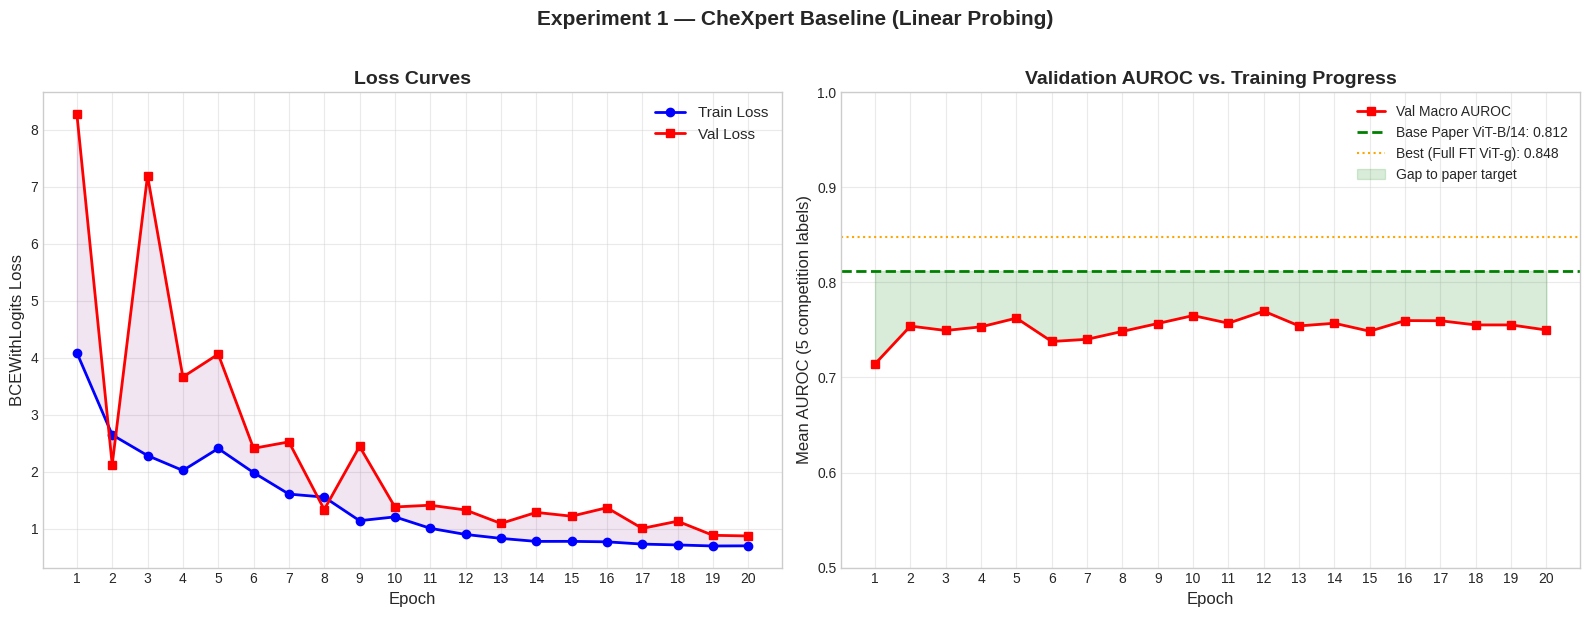

Saved: loss_auroc_curves.png


In [31]:
"""
Plot training and validation loss curves alongside AUROC curves per epoch.
Reference line marks the base paper's reported AUROC for DINOv2 ViT-B/14.
"""
epochs_x = range(1, len(history["epoch"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Loss Curves
axes[0].plot(epochs_x, history["train_loss"], "b-o", label="Train Loss", linewidth=2, markersize=6)
axes[0].plot(epochs_x, history["val_loss"], "r-s", label="Val Loss", linewidth=2, markersize=6)
axes[0].fill_between(epochs_x, history["train_loss"], history["val_loss"], alpha=0.1, color="purple")
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("BCEWithLogits Loss", fontsize=12)
axes[0].set_title("Loss Curves", fontsize=14, fontweight="bold")
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.4)
axes[0].set_xticks(list(epochs_x))

# 2. Validation AUROC
axes[1].plot(epochs_x, history["val_macro_auroc"], "r-s", label="Val Macro AUROC", linewidth=2, markersize=6)
axes[1].axhline(y=0.812, color="green", linestyle="--", linewidth=2, label="Base Paper ViT-B/14: 0.812")
axes[1].axhline(y=0.848, color="orange", linestyle=":", linewidth=1.5, label="Best (Full FT ViT-g): 0.848")
axes[1].fill_between(epochs_x, history["val_macro_auroc"],
                     [0.812] * len(history["val_macro_auroc"]), alpha=0.15, color="green",
                     label="Gap to paper target")
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Mean AUROC (5 competition labels)", fontsize=12)
axes[1].set_title("Validation AUROC vs. Training Progress", fontsize=14, fontweight="bold")
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.4)
axes[1].set_xticks(list(epochs_x))
axes[1].set_ylim(0.5, 1.0)

plt.suptitle("Experiment 1 — CheXpert Baseline (Linear Probing)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/loss_auroc_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: loss_auroc_curves.png")

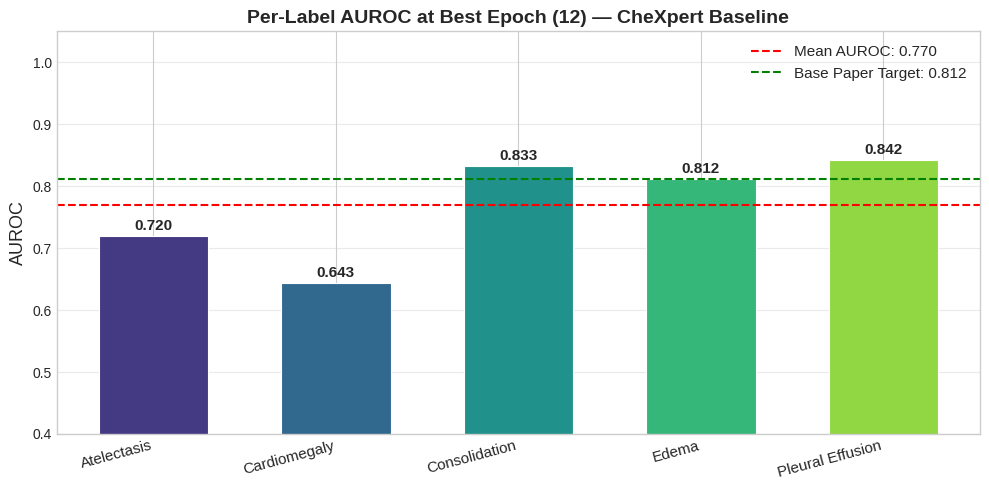

In [ ]:
"""
Bar chart of per-label AUROC at the best validation epoch.
"""
best_per_label = history["per_label_auroc"][best_epoch - 1]
labels = list(best_per_label.keys())
values = list(best_per_label.values())

fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette("viridis", NUM_LABELS)
bars = ax.bar(labels, values, color=colors, edgecolor="white", linewidth=0.8, width=0.6)

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005, f"{v:.3f}",
            ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.axhline(y=best_val_auroc, color="red", linestyle="--", linewidth=1.5,
           label=f"Mean AUROC: {best_val_auroc:.3f}")
ax.axhline(y=0.812, color="green", linestyle="--", linewidth=1.5,
           label="Base Paper Target: 0.812")

ax.set_ylabel("AUROC", fontsize=13)
ax.set_title(f"Per-Label AUROC at Best Epoch ({best_epoch}) — CheXpert Baseline",
             fontsize=14, fontweight="bold")

# Explicitly set tick positions first to suppress the Matplotlib UserWarning
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=11)

ax.legend(fontsize=11)
ax.set_ylim(0.4, 1.05)
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/per_label_auroc.png", dpi=150, bbox_inches="tight")
plt.show()

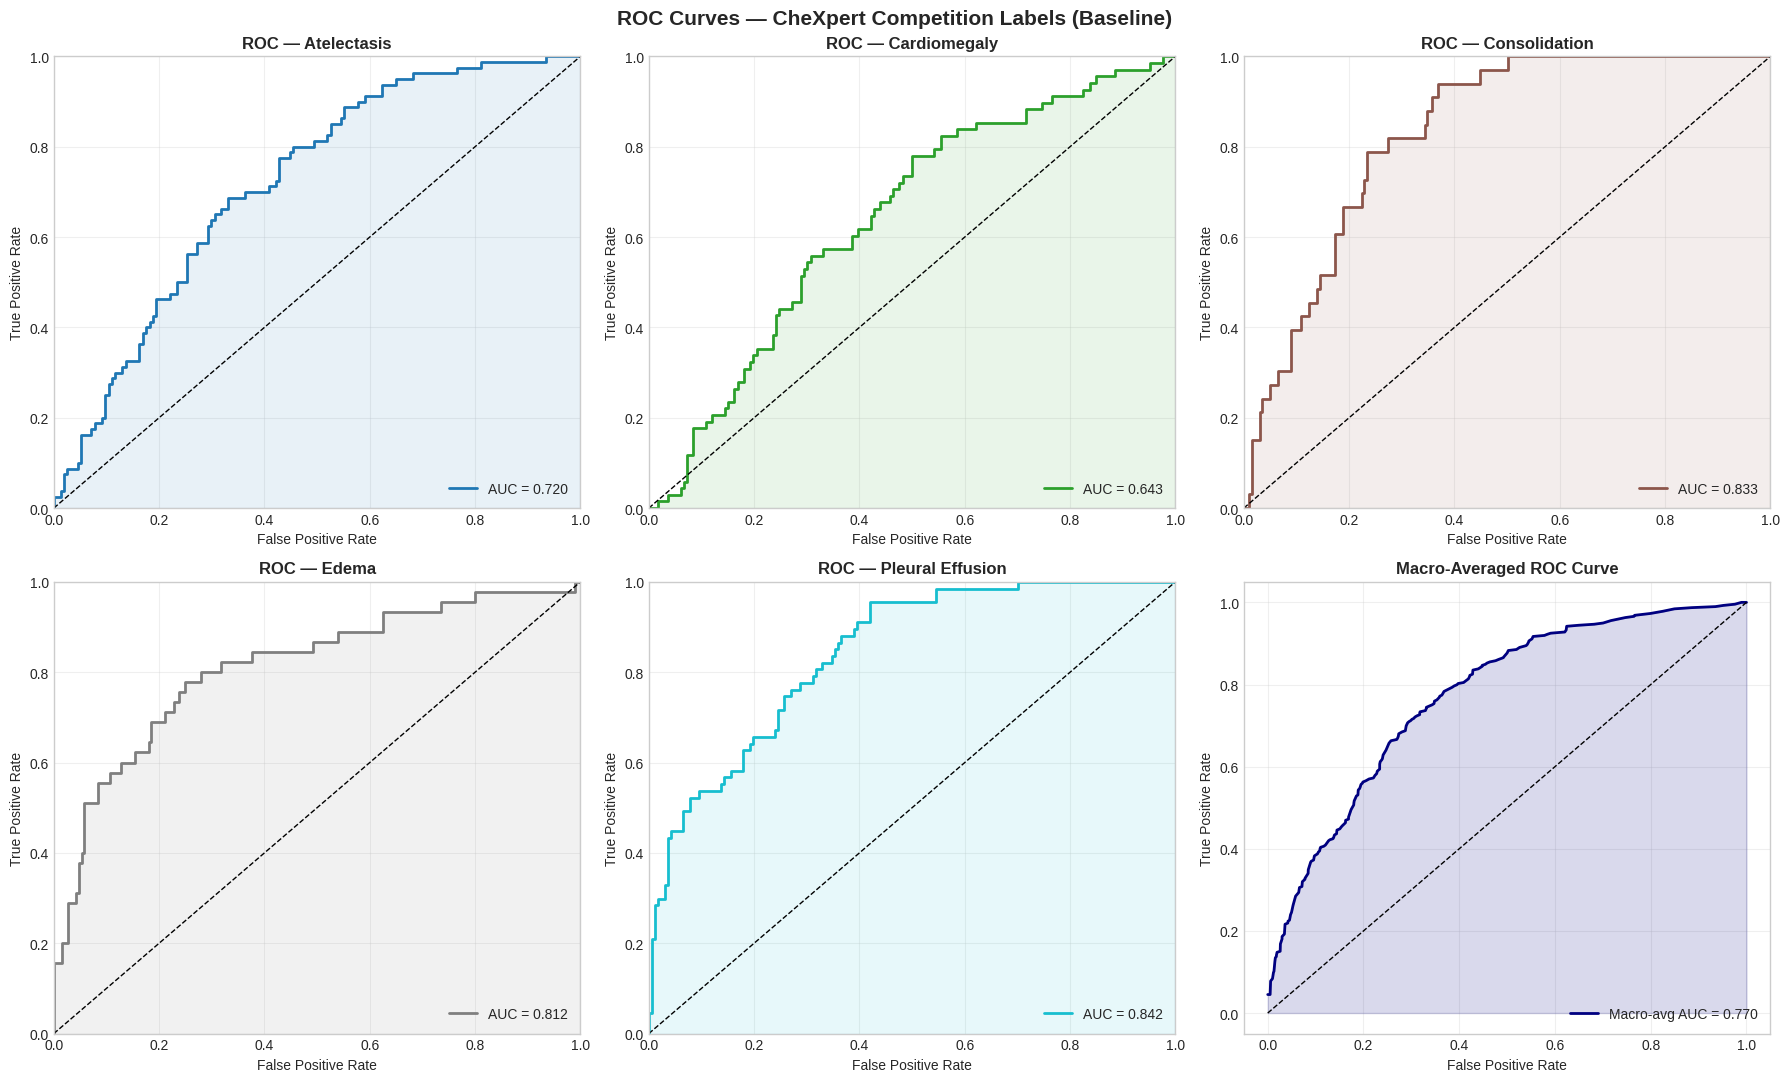

In [33]:
"""
Plot individual ROC curves for each competition label plus macro-averaged ROC.
Load best checkpoint for final evaluation.
"""
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import roc_curve as sk_roc
import numpy as np
import torch
import matplotlib.pyplot as plt

def sigmoid_np(x):
    return 1 / (1 + np.exp(-x))

# Load 'best_chexpert_linear_probe.pt' instead of 'best_model.pt', and use 'device' instead of 'DEVICE'
model.head.load_state_dict(torch.load(f"{CHECKPOINT_DIR}/best_chexpert_linear_probe.pt", map_location=device))
model.eval()

all_logits: list[torch.Tensor] = []
all_labels_list: list[torch.Tensor] = []
with torch.no_grad():
    for batch in val_loader:
        pv = batch["pixel_values"].to(device, non_blocking=True)
        all_logits.append(model(pv).cpu())
        all_labels_list.append(batch["labels"])

final_logits = torch.cat(all_logits, dim=0).float().numpy()
final_labels = torch.cat(all_labels_list, dim=0).float().numpy()
final_probs = sigmoid_np(final_logits)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()
colors_roc = plt.cm.tab10(np.linspace(0, 1, NUM_LABELS))

for i, (label_name, color) in enumerate(zip(COMPETITION_LABELS, colors_roc)):
    fpr, tpr, _ = roc_curve(final_labels[:, i], final_probs[:, i])
    auc_score = roc_auc_score(final_labels[:, i], final_probs[:, i])
    axes[i].plot(fpr, tpr, color=color, lw=2, label=f"AUC = {auc_score:.3f}")
    axes[i].plot([0, 1], [0, 1], "k--", lw=1)
    axes[i].fill_between(fpr, tpr, alpha=0.1, color=color)
    axes[i].set_xlabel("False Positive Rate")
    axes[i].set_ylabel("True Positive Rate")
    axes[i].set_title(f"ROC — {label_name}", fontweight="bold")
    axes[i].legend(loc="lower right")
    axes[i].grid(alpha=0.3)
    axes[i].set_xlim(0, 1)
    axes[i].set_ylim(0, 1)

all_fpr = np.unique(np.concatenate([roc_curve(final_labels[:, i], final_probs[:, i])[0] for i in range(NUM_LABELS)]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(NUM_LABELS):
    fpr_i, tpr_i, _ = sk_roc(final_labels[:, i], final_probs[:, i])
    mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
mean_tpr /= NUM_LABELS

axes[5].plot(all_fpr, mean_tpr, color="navy", lw=2,
             label=f"Macro-avg AUC = {best_val_auroc:.3f}")
axes[5].plot([0, 1], [0, 1], "k--", lw=1)
axes[5].fill_between(all_fpr, mean_tpr, alpha=0.15, color="navy")
axes[5].set_xlabel("False Positive Rate")
axes[5].set_ylabel("True Positive Rate")
axes[5].set_title("Macro-Averaged ROC Curve", fontweight="bold")
axes[5].legend(loc="lower right")
axes[5].grid(alpha=0.3)

plt.suptitle("ROC Curves — CheXpert Competition Labels (Baseline)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CHECKPOINT_DIR}/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
"""
Final results table comparing our experiment against the base paper benchmarks.
"""
final_macro_f1 = float(
    f1_score(
        (final_labels >= 0.5).astype(int),
        (final_probs >= 0.5).astype(int),
        average="macro",
        zero_division=0,
    )
)

results_comparison = {
    "Experiment": [
        "DINOv2 ViT-B/14 — Linear Probe (Ours, 10k subset)",
        "DINOv2 ViT-B/14 — Linear Probe (Base Paper, full data)",
        "DINOv2 ViT-L/14 — Linear Probe (Base Paper)",
        "DINOv2 ViT-g/14 — Linear Probe (Base Paper)",
        "DINOv2 ViT-g/14 — LoRA PEFT (Base Paper)",
        "DINOv2 ViT-g/14 — Full Fine-Tune (Base Paper)",
    ],
    "Backbone": ["ViT-B/14"] * 2 + ["ViT-L/14", "ViT-g/14", "ViT-g/14", "ViT-g/14"],
    "Method": ["LinearProbe", "LinearProbe", "LinearProbe", "LinearProbe", "LoRA", "FullFT"],
    "AUROC": [
        round(best_val_auroc, 4),
        0.812, 0.821, 0.818, 0.823, 0.848
    ],
    "Source": ["This Experiment"] + ["Base Paper"] * 5,
}

results_df = pd.DataFrame(results_comparison)
results_df["Delta vs. ViT-B/14 Base"] = (results_df["AUROC"] - 0.812).round(4)
results_df["Delta vs. ViT-B/14 Base"] = results_df["Delta vs. ViT-B/14 Base"].apply(
    lambda x: f"+{x:.4f}" if x > 0 else f"{x:.4f}"
)

print("=" * 80)
print("EXPERIMENT 1 — RESULTS TABLE (CheXpert Linear Probing Baseline)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)
print(f"\nOur Best Val AUROC:   {best_val_auroc:.4f}")
print(f"Base Paper Target:     0.8120")
print(f"Delta:                 {best_val_auroc - 0.812:+.4f}")
print(f"Our Macro-F1 (val):   {final_macro_f1:.4f}")
print(f"Best Epoch:            {best_epoch}")
print(f"Trainable Params:      {trainable_params:,}")

EXPERIMENT 1 — RESULTS TABLE (CheXpert Linear Probing Baseline)
                                            Experiment Backbone      Method  AUROC          Source Delta vs. ViT-B/14 Base
     DINOv2 ViT-B/14 — Linear Probe (Ours, 10k subset) ViT-B/14 LinearProbe  0.770 This Experiment                 -0.0422
DINOv2 ViT-B/14 — Linear Probe (Base Paper, full data) ViT-B/14 LinearProbe  0.812      Base Paper                  0.0000
           DINOv2 ViT-L/14 — Linear Probe (Base Paper) ViT-L/14 LinearProbe  0.821      Base Paper                 +0.0090
           DINOv2 ViT-g/14 — Linear Probe (Base Paper) ViT-g/14 LinearProbe  0.818      Base Paper                 +0.0060
              DINOv2 ViT-g/14 — LoRA PEFT (Base Paper) ViT-g/14        LoRA  0.823      Base Paper                 +0.0110
         DINOv2 ViT-g/14 — Full Fine-Tune (Base Paper) ViT-g/14      FullFT  0.848      Base Paper                 +0.0360

Our Best Val AUROC:   0.7698
Base Paper Target:     0.8120
Delta:         